Colab is an online place (cloud) for running Python notebooks--we will use it to produce descriptive stats and regressions

You can just edit and adjust and and run the notebook I gave you [this file!]: don't forget to first save it!!!: File-Save a copy in Drive (it will save it in your google drive)

And then just adjust it to run with your own data

Make webbrowser fullscreen and collapse upper menu (arrow on the right), especially on laptop

should be able to run ols regression even in excel, eg
https://www.google.com/search?q=run+ols+regression+in+excel&rlz=1CAHWSA_enUS1125US1125&oq=run+ols+regression+in+excel&gs_lcrp=EgZjaHJvbWUyBggAEEUYOTIICAEQABgWGB4yCAgCEAAYFhgeMggIAxAAGBYYHjINCAQQABiGAxiABBiKBTINCAUQABiGAxiABBiKBTINCAYQABiGAxiABBiKBTIKCAcQABiABBiiBDIKCAgQABiABBiiBNIBCDUxNDRqMGo3qAIAsAIA&sourceid=chrome&ie=UTF-8

https://www3.wabash.edu/econometrics/EconometricsBook/Basic%20Tools/ExcelAddIns/OLSRegression.htm

but much better use modern software like Python, see below

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as sm
import seaborn as sns

import matplotlib.pyplot as plt
plt.style.use('bmh')

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

### height and self esteem

In [ ]:
#note that first need to put your data online eg see howto:
#https://theaok.github.io/generic/howToPutDataOnline.html
dat=pd.read_csv('https://drive.google.com/uc?id=1YH8DfzsQ8suZkVQBk7T9FTKvvm9Vyej8&export=download')
dat.head(5)

,Person,Height,Self Esteem
0,1,68,4.1
1,2,71,4.6
2,3,62,3.8
3,4,75,4.4
4,5,58,3.2


In [ ]:
dat["Height"].mean() # median, mode, stdev
dat["Height"].median()

65.4

66.0

In [ ]:
dat[['Height','Self Esteem']].corr().round(2)

,Height,Self Esteem
Height,1.00,0.73
Self Esteem,0.73,1.00


<Axes: >

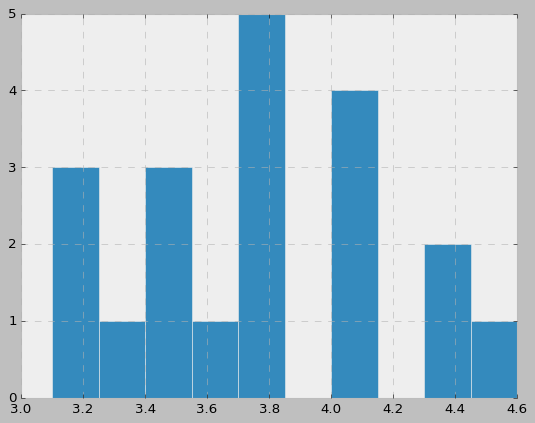

In [ ]:
dat["Self Esteem"].hist()

<Axes: xlabel='Height', ylabel='Self Esteem'>

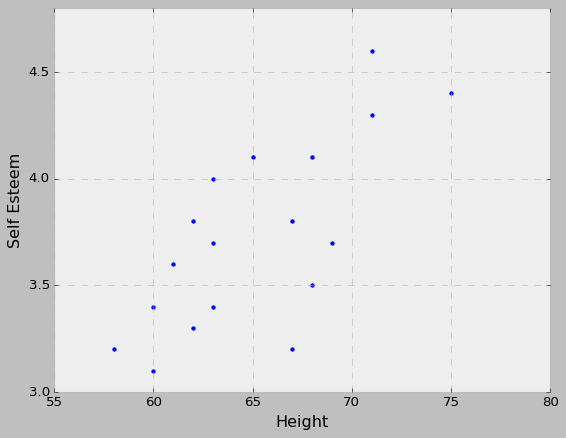

In [ ]:
dat.plot(kind='scatter', y='Self Esteem', x='Height')

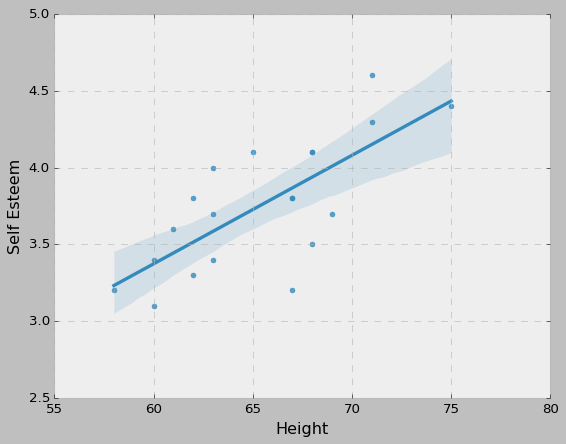

In [ ]:
sns.regplot(y="Self Esteem", x="Height", data=dat);

do pay attention to scales, so say if height goes up by say from 60 to 70, self esteem goes up by about .7, which is 10 * beta coef in regression below

In [ ]:
result = sm.ols(formula="dat['Self Esteem'] ~ Height", data=dat).fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:     dat['Self Esteem']   R-squared:                       0.534
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     20.61
Date:                Sun, 03 Nov 2024   Prob (F-statistic):           0.000254
Time:                        14:21:42   Log-Likelihood:                -3.1717
No. Observations:                  20   AIC:                             10.34
Df Residuals:                      18   BIC:                             12.33
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8663      1.020     -0.849      0.4

### wages

In [ ]:
wages=pd.read_stata('https://github.com/theaok/data/raw/refs/heads/main/wages.dta')

In [ ]:
wages.head(5)

,wage,educ,exp,union,nonwhite,hispanic,female,married,south,_est_logit,wageQ
0,4.9998,12,4,no,no,no,male,no,yes,1,1
1,17.2500,18,5,no,no,no,male,yes,no,1,4
2,9.8601,15,13,no,no,no,male,yes,no,1,3
3,14.9990,12,39,yes,no,no,male,yes,no,1,4
4,4.0000,12,4,no,no,no,male,no,no,1,0


In [ ]:
#wages['wage'].quantile(0.2)
wages['expQ'] = pd.qcut(wages['exp'], 5, labels=False)

<Axes: xlabel='female', ylabel='wage'>

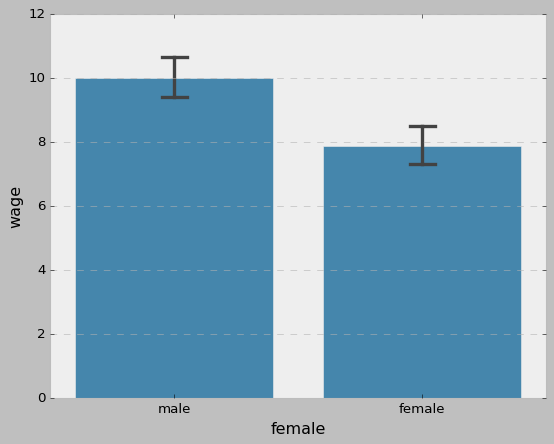

In [ ]:
sns.barplot(data=wages, y='wage', x='female', estimator=np.mean, errorbar=('ci', 95), capsize=.1, orient='v')

<Axes: xlabel='expQ', ylabel='wage'>

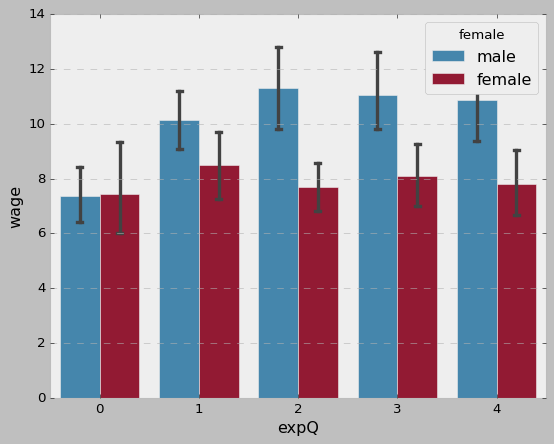

In [ ]:
sns.barplot(data=wages, y='wage', x='expQ', hue='female', estimator=np.mean, errorbar=('ci', 95), capsize=.1, orient='v')

<Axes: xlabel='female', ylabel='wage'>

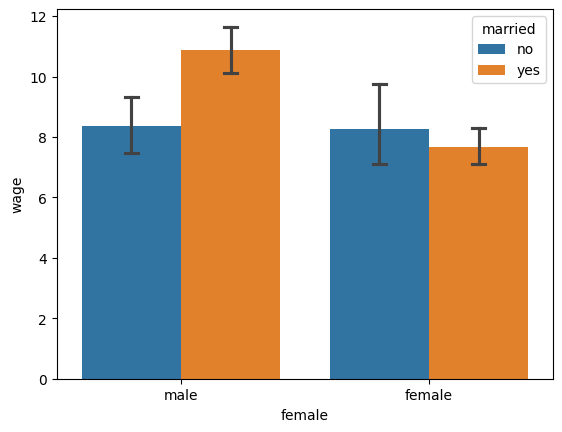

In [ ]:
sns.barplot(data=wages, y='wage', x='female', hue='married', estimator=np.mean, errorbar=('ci', 95), capsize=.1, orient='v')

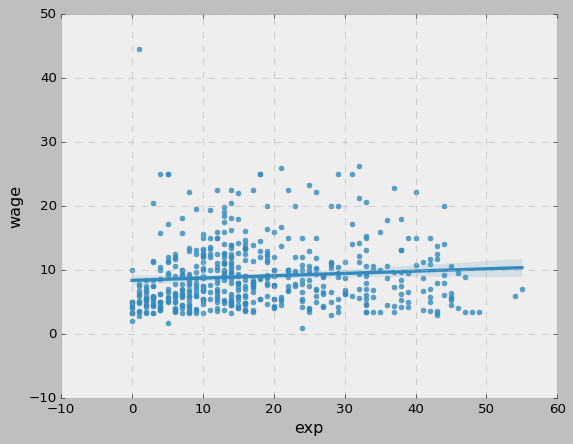

In [ ]:
sns.regplot(x="exp", y="wage", data=wages);

<Axes: >

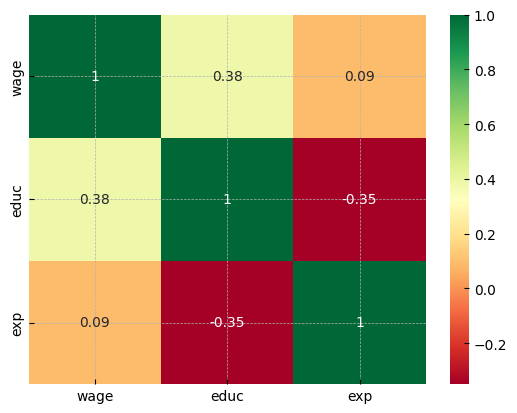

In [ ]:
sns.heatmap(wages[['wage','educ','exp']].corr().round(2),cmap="RdYlGn",annot=True)

In [ ]:
result = sm.ols(formula="wage ~ educ + exp + married", data=wages).fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                   wage   R-squared:                       0.205
Model:                            OLS   Adj. R-squared:                  0.200
Method:                 Least Squares   F-statistic:                     45.45
Date:                Tue, 29 Oct 2024   Prob (F-statistic):           3.78e-26
Time:                        20:12:18   Log-Likelihood:                -1570.2
No. Observations:                 534   AIC:                             3148.
Df Residuals:                     530   BIC:                             3165.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         -5.0704      1.225     -4.

another example:

https://www.learndatasci.com/tutorials/predicting-housing-prices-linear-regression-using-python-pandas-statsmodels/